# European contract pricing with Tree

In [1]:
import numpy as np
from scipy.optimize import minimize
from collections.abc import Callable

## Create European contract payoff

In [2]:
def european_call_payoff(S: float, K: float) -> float:
    return max(S-K, 0.0)

## Create Spot Tree

In [3]:
def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree

In [4]:
spot = 1
spot_mult_up = 1.2
spot_mult_down = 0.8
steps = 2
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'], ['0.800', '1.200'], ['0.640', '0.960', '1.440']]

## Create Price Tree

In [5]:
def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float, diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print(('%.3f' % p_up, '%.3f' % p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [6]:
discount_factor = 0.95
strike = 1
diag = 1
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
('0.632', '0.368')
delta: 
[['0.366'], ['-0.000', '0.827']]
Price tree:


[['0.054'], ['0.000', '0.146'], ['0.000', '0.000', '0.397']]

In [7]:
pv_up_up = 0.44*0.95*0.95
print('%.3f' % pv_up_up)

0.397


In [8]:
mid_step = 0.3971 * 0.3684210526315791
print('%.3f' % mid_step)

0.146


## Balanced Tree

In [9]:
def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> (float, float):
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

In [10]:
print("spot_mult_up: " + str('%.3f' %spot_mult_up))
spot_mult_down_balanced = calcBalancedDownStep(spot_mult_up, discount_factor)
print("spot_mult_down: " + str('%.3f' %spot_mult_down_balanced))
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down_balanced, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
print("spot_tree: " + str(spot_tree_readable))
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree: " + str(price_tree_readable))

spot_mult_up: 1.200
spot_mult_down: 0.905
spot_tree: [['1.000'], ['0.905', '1.200'], ['0.820', '1.086', '1.440']]
risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.674'], ['0.292', '0.903']]
price tree: [['0.138'], ['0.039', '0.237'], ['0.000', '0.078', '0.397']]


## Delta is close to 0.5 for At The Money Forward option

In [11]:
strike_ATMF = 1/0.95**2
price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike_ATMF, 1)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("price tree:")
price_tree_readable

risk-neutral measure: 
('0.500', '0.500')
delta: 
[['0.508'], ['-0.000', '0.847']]
price tree:


[['0.075'], ['0.000', '0.150'], ['0.000', '0.000', '0.300']]

## Barrier options

In [12]:
def up_and_out(B: float) -> Callable[[float], float]:
    def knock_multiplier(s: float) -> float:
        return 1.0 if (s < B) else 0.0
    return knock_multiplier

In [13]:
def create_discounted_price_tree_ko(spot_tree: list[list[float]], discount_factor: float, K: float, ko_function: Callable[[float], float], diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print((p_up, p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K) * ko_function(spot)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            continuation_value_tree[step][i] *= ko_function(spot_tree[step][i])
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
                delta_tree[step][i] *= ko_function(spot_tree[step][i])
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

In [14]:
# create spot tree
spot = 1
maturity = 1 # years
steps_per_year = 7
steps = steps_per_year * maturity
discount_factor = 0.95 ** (1./steps_per_year) # discount factors have to be scaled to keep interest rate fixed
spot_mult_up = np.exp((0.05 - 0.5 * 0.1 ** 2) / steps_per_year + 0.1 * np.sqrt(1./steps_per_year)) # step sizes are scaled as well
spot_mult_down = calcBalancedDownStep(spot_mult_up, discount_factor)
spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
spot_tree_readable = [['%.3f' % e for e in n] for n in spot_tree]
spot_tree_readable

[['1.000'],
 ['0.969', '1.045'],
 ['0.940', '1.013', '1.092'],
 ['0.911', '0.982', '1.059', '1.142'],
 ['0.883', '0.952', '1.027', '1.107', '1.194'],
 ['0.856', '0.923', '0.996', '1.073', '1.157', '1.247'],
 ['0.830', '0.895', '0.965', '1.041', '1.122', '1.209', '1.304'],
 ['0.805', '0.868', '0.936', '1.009', '1.088', '1.173', '1.264', '1.363']]

In [15]:
# create price tree
strike = 1
barrier = 1.2
barrier_condition = up_and_out(barrier)
diag = 1
price_tree = create_discounted_price_tree_ko(spot_tree, discount_factor, strike, barrier_condition, diag)
price_tree_readable = [['%.3f' % e for e in n] for n in price_tree]
print("Price tree:")
price_tree_readable

risk-neutral measure: 
(np.float64(0.5), np.float64(0.5))
delta: 
[['0.246'], ['0.386', '0.113'], ['0.378', '0.389', '-0.145'], ['0.181', '0.555', '0.229', '-0.490'], ['0.031', '0.317', '0.768', '-0.273', '-0.683'], ['-0.000', '0.060', '0.552', '0.957', '-1.410', '-0.000'], ['-0.000', '-0.000', '0.114', '0.950', '0.950', '-0.000', '-0.000']]
Price tree:


[['0.044'],
 ['0.035', '0.054'],
 ['0.021', '0.049', '0.058'],
 ['0.007', '0.034', '0.064', '0.052'],
 ['0.001', '0.014', '0.055', '0.073', '0.031'],
 ['0.000', '0.002', '0.025', '0.085', '0.062', '0.000'],
 ['0.000', '0.000', '0.004', '0.046', '0.124', '0.000', '0.000'],
 ['0.000', '0.000', '0.000', '0.008', '0.083', '0.164', '0.000', '0.000']]

## Q: How would you model continuous barrier better?

In [16]:
# Homework - Tree calibration

from scipy.optimize import brentq
from scipy.stats import norm
import matplotlib.pyplot as plt


def bsm_call(S0, K, T, r, sigma):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r*T) * norm.cdf(d2)


def tree_call_price(S0, K, T, r, steps, up):
    discount_factor = np.exp(-r*T/steps)
    down = calcBalancedDownStep(up, discount_factor)
    spot_tree = create_spot_tree(1.0, up, down, steps)

    return S0 * create_discounted_price_tree(
        spot_tree, discount_factor, K/S0
    )[0][0]


def calibrate(S0, K, T, r, steps, target_price):
    growth = np.exp(r*T/steps)
    lower = growth * (1 + 1e-10)
    upper = growth * (2 - 1e-10)

    def error(up):
        return tree_call_price(S0, K, T, r, steps, up) - target_price

    if error(lower) * error(upper) > 0:
        raise ValueError("Target price cannot be matched by this balanced tree")

    up = brentq(error, lower, upper, xtol=1e-12)
    down = calcBalancedDownStep(up, np.exp(-r*T/steps))

    return up, down

Target BSM call price: 0.10450584
N= 1: up=1.219728, down=0.882814, tree price=0.10450584
N= 2: up=1.175628, down=0.875002, tree price=0.10450584
N= 4: up=1.113772, down=0.911385, tree price=0.10450584
N= 8: up=1.076632, down=0.935907, tree price=0.10450584
N=16: up=1.052727, down=0.953532, tree price=0.10450584
N=32: up=1.036700, down=0.966428, tree price=0.10450584
N=64: up=1.025707, down=0.975856, tree price=0.10450584


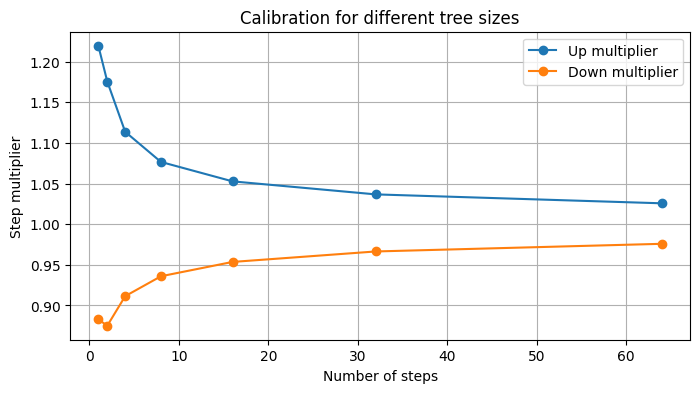

In [17]:
# Same contract, different numbers of tree steps

S0, K, T, r, sigma = 1.0, 1.0, 1.0, 0.05, 0.20

target_price = bsm_call(S0, K, T, r, sigma)

step_counts = [1, 2, 4, 8, 16, 32, 64]
up_values, down_values = [], []

print(f"Target BSM call price: {target_price:.8f}")

for steps in step_counts:
    up, down = calibrate(S0, K, T, r, steps, target_price)
    price = tree_call_price(S0, K, T, r, steps, up)

    assert abs(price - target_price) < 1e-9

    up_values.append(up)
    down_values.append(down)

    print(f"N={steps:2d}: up={up:.6f}, down={down:.6f}, tree price={price:.8f}")

plt.figure(figsize=(8, 4))
plt.plot(step_counts, up_values, 'o-', label='Up multiplier')
plt.plot(step_counts, down_values, 'o-', label='Down multiplier')
plt.xlabel('Number of steps')
plt.ylabel('Step multiplier')
plt.title('Calibration for different tree sizes')
plt.grid(True)
plt.legend()
plt.show()

T=0.5, K=0.9: up=1.176805, down=0.873826, call=0.134985
T=0.5, K=1.0: up=1.141262, down=0.909368, call=0.068887
T=0.5, K=1.1: up=1.159601, down=0.891029, call=0.029065
T=1.0, K=0.9: up=1.251113, down=0.851429, call=0.166994
T=1.0, K=1.0: up=1.219728, down=0.882814, call=0.104506
T=1.0, K=1.1: up=1.226995, down=0.875547, call=0.060401
T=2.0, K=0.9: up=1.387013, down=0.823329, call=0.220334
T=2.0, K=1.0: up=1.356457, down=0.853885, call=0.161268
T=2.0, K=1.1: up=1.353205, down=0.857137, call=0.114555


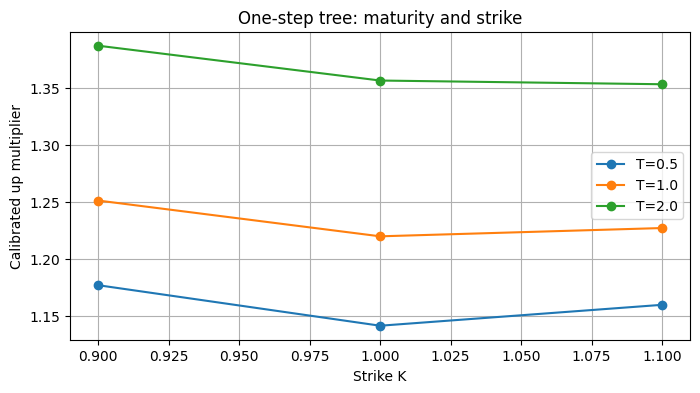

In [18]:
# One-step tree, different maturities and strike prices

maturities = [0.5, 1.0, 2.0]
strikes = [0.9, 1.0, 1.1]

plt.figure(figsize=(8, 4))

for T in maturities:
    calibrated_ups = []

    for K in strikes:
        target_price = bsm_call(S0, K, T, r, sigma)
        up, down = calibrate(S0, K, T, r, 1, target_price)
        price = tree_call_price(S0, K, T, r, 1, up)

        assert abs(price - target_price) < 1e-9

        calibrated_ups.append(up)

        print(f"T={T:.1f}, K={K:.1f}: up={up:.6f}, down={down:.6f}, call={price:.6f}")

    plt.plot(strikes, calibrated_ups, 'o-', label=f'T={T}')

plt.xlabel('Strike K')
plt.ylabel('Calibrated up multiplier')
plt.title('One-step tree: maturity and strike')
plt.grid(True)
plt.legend()
plt.show()